In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmcrameri import cm
import seaborn as sns
import re

plt.style.use('./libs/notebookstyle_aps.mplstyle')

%load_ext autoreload
%autoreload 2

In [2]:
dfq = pd.read_csv('./QNN_results/QNN_r2.txt', header =0, index_col = None)

def parse_config(s):
    match = re.match(r"(\d+)qubits_circuit_([a-zA-Z]+)_([a-zA-Z]+)_freq(\d+)enc_(\d+)dec_([a-zA-Z]+)", s)
    if match:
        qubits, enc_angles, angles, n_enc, n_dec,  entanglement = match.groups()
        return int(qubits), int(n_enc), int(n_dec), entanglement, angles, enc_angles
    return None, None, None, None

dfq[['n_qubits', 'n_enc', 'n_dec', 'entanglement','angles','enc_angles']] = dfq['model_name'].apply(
    lambda x: pd.Series(parse_config(x))
)

dfq['nonlocal'] = (dfq.entanglement == 'nonlocal')*1.
dfq['n_params'] = dfq.n_qubits*(dfq.n_enc + dfq.n_dec)*dfq.angles.apply(lambda s: len(s)) + dfq.n_qubits*dfq.n_enc*dfq.enc_angles.apply(lambda s: len(s))

In [3]:
dfq = dfq.reset_index()
key_map = {str(k): i for i, k in enumerate(np.unique(dfq.key.values))}
dfq["key_id"] = dfq["key"].astype(str).map(key_map)

### Figure with Overview of validation R² for SI

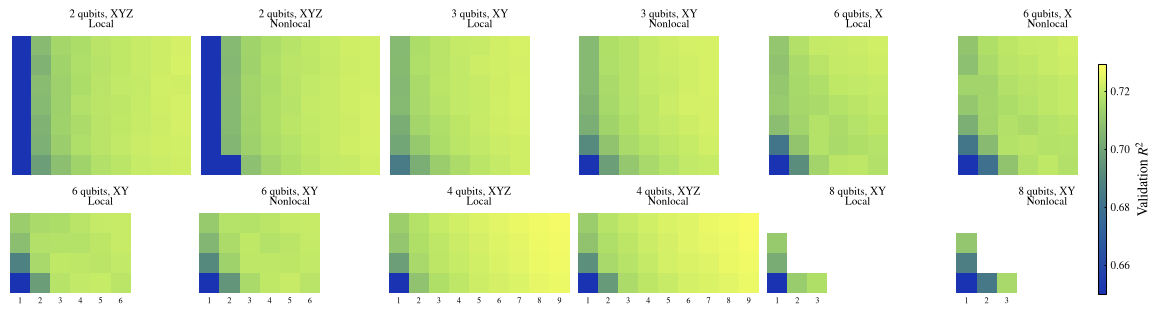

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
import seaborn as sns

fig, axs = plt.subplots(
    2, 6,
    figsize=(11.5, 3.2),
    constrained_layout=True,
)
configs = [
    dict(n_qubits=2, enc_angles="XYZ", label="2 qubits, XYZ"),
    dict(n_qubits=3, enc_angles="XY",  label="3 qubits, XY"),
    dict(n_qubits=6, enc_angles="X",   label="6 qubits, X"),
    dict(n_qubits=6, enc_angles="XY",  label="6 qubits, XY"),
    dict(n_qubits=4, enc_angles="XYZ", label="4 qubits, XYZ"),
    dict(n_qubits=8, enc_angles="XY",  label="8 qubits, XY"),
]
# one norm object, used for heatmaps & the colorbar so they always agree
vmin, vmax = 0.65, dfq.r2_val.max()
norm = Normalize(vmin, vmax)

for row in range(2):
    # per-row grid: each row only spans the enc/dec values it actually has
    row_cfgs = configs[3 * row: 3 * row + 3]
    dfrow = pd.concat([
        dfq[(dfq.n_qubits == cfg["n_qubits"]) & (dfq.enc_angles == cfg["enc_angles"])]
        for cfg in row_cfgs
    ])
    enc_vals = np.sort(dfrow.n_enc.unique())
    dec_vals = np.sort(dfrow.n_dec.unique())

    for j, cfg in enumerate(row_cfgs):
        c = j * 2
        ax_local = axs[row, c]
        ax_nonlocal = axs[row, c + 1]

        dfsub = dfq[(dfq.n_qubits == cfg["n_qubits"]) & (dfq.enc_angles == cfg["enc_angles"])]

        for ax, kind in [(ax_local, "Local"), (ax_nonlocal, "Nonlocal")]:
            pivot = dfsub[dfsub["nonlocal"] == (0 if kind == "Local" else 1)].pivot_table(
                columns="n_enc", index="n_dec", values="r2_val", aggfunc="mean"
            ).reindex(index=dec_vals, columns=enc_vals)
            if pivot.empty or not pivot.notna().any().any():
                ax.set_axis_off()
                continue
            sns.heatmap(
                pivot, ax=ax, cmap=cm.imola,
                norm=norm,
                cbar=False,
                square=True,
            )
            ax.set_title(f"{cfg['label']}\n{kind}", fontsize=8)
            ax.invert_yaxis()

            col_has = pivot.notna().any(axis=0)
            row_has = pivot.notna().any(axis=1)
            
            ax.set_xticks(np.arange(len(enc_vals)) + 0.5)
            ax.set_xticklabels(
                [str(int(v)) if (row == 1 and col_has.iloc[i]) else "" for i, v in enumerate(enc_vals)],
                fontsize=6,
            )
            ax.set_yticks(np.arange(len(dec_vals)) + 0.5)
            ax.set_yticklabels(
                [str(int(v)) if (c == 0 and row_has.iloc[i] and j == 'Local') else "" for i, v in enumerate(dec_vals)],
                fontsize=6,
            )
            ax.tick_params(length=0, pad=3, labelsize=6)

            ax.set_xlabel("number of encoding layers" if (row == 1)&(j == 'Local') else "", fontsize=7)
            ax.set_ylabel("number of decoding layers" if (c == 0)&(j == 'Local') else "", fontsize=7)

sm = plt.cm.ScalarMappable(cmap=cm.imola, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs, aspect=30, pad=-0.035, shrink = 0.8)
cbar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
cbar.set_label("Validation $R^2$")
cbar.ax.tick_params( length=1.5)

fig.savefig("./figures/QNN_layers.pdf", bbox_inches="tight")